
# Hyperparameter Optimization Using Optuna

## Objective
Optimize six machine learning regression models for predicting CO₂ uptake (mmol/g) in biomass-derived porous carbons.

## Models
1. Random Forest
2. Extra Trees
3. Gradient Boosting
4. XGBoost
5. LightGBM
6. CatBoost

## Methodology
- Use the existing training, validation, and test assignments.
- Optimize hyperparameters using Optuna.
- Evaluate candidate configurations through 3-fold cross-validation on the training set.
- Select hyperparameters by minimizing cross-validated RMSE.
- Refit each optimized pipeline on the complete training set.
- Evaluate optimized models on the validation set using MAE, RMSE, and R².
- Save trial histories, best parameters, trained pipelines, and comparison results.

The test set remains untouched until final evaluation.


In [1]:

from pathlib import Path
import json
import time
import warnings

import joblib
import numpy as np
import pandas as pd
import optuna

from sklearn.base import clone
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import KFold, cross_val_score
from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor,
    GradientBoostingRegressor,
)
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)

from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor

warnings.filterwarnings("ignore", category=FutureWarning)
optuna.logging.set_verbosity(optuna.logging.WARNING)

RANDOM_STATE = 42
N_TRIALS = 20
N_SPLITS = 3

current_dir = Path.cwd()
possible_roots = [current_dir, current_dir.parent]

PROJECT_ROOT = next(
    (
        path for path in possible_roots
        if (path / "data" / "Processed_527_datapoints.csv").exists()
        and (path / "artifacts" / "feature_config.json").exists()
    ),
    None,
)

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Project root not found. Open Jupyter from the project "
        "root or its notebooks folder."
    )

DATA_PATH = PROJECT_ROOT / "data" / "Processed_527_datapoints.csv"
SPLIT_PATH = PROJECT_ROOT / "artifacts" / "splits" / "split_assignments.csv"
FEATURE_CONFIG_PATH = PROJECT_ROOT / "artifacts" / "feature_config.json"

RESULTS_DIR = PROJECT_ROOT / "results"
TRIALS_DIR = RESULTS_DIR / "optuna_trials"
TUNED_MODEL_DIR = PROJECT_ROOT / "artifacts" / "tuned_models"

for directory in [RESULTS_DIR, TRIALS_DIR, TUNED_MODEL_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Optuna version:", optuna.__version__)
print("Trials per model:", N_TRIALS)
print("Cross-validation folds:", N_SPLITS)


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Project root: /Users/divyakandlakuti/Desktop/interpretable-co2-adsorption-ml
Optuna version: 5.0.0
Trials per model: 20
Cross-validation folds: 3


In [2]:

df = pd.read_csv(DATA_PATH)
split_assignments = pd.read_csv(SPLIT_PATH)

with open(FEATURE_CONFIG_PATH, "r", encoding="utf-8") as file:
    feature_config = json.load(file)

TARGET_COLUMN = feature_config["target"]
FEATURE_COLUMNS = feature_config["features"]

df = df.drop_duplicates().reset_index(drop=True)

if "row_id" not in df.columns:
    df.insert(0, "row_id", np.arange(len(df)))

if df["row_id"].duplicated().any():
    raise ValueError("Dataset contains duplicate row_id values.")

if split_assignments["row_id"].duplicated().any():
    raise ValueError("Split file contains duplicate row_id values.")

data = df.merge(
    split_assignments[["row_id", "split"]],
    on="row_id",
    how="inner",
    validate="one_to_one",
)

if len(data) != len(split_assignments):
    raise ValueError(
        "Split assignments did not all match the dataset. "
        "Do not regenerate the split; inspect row_id alignment."
    )

if TARGET_COLUMN not in data.columns:
    raise KeyError(f"Target column missing: {TARGET_COLUMN}")

missing_features = [
    col for col in FEATURE_COLUMNS if col not in data.columns
]
if missing_features:
    raise KeyError(f"Missing feature columns: {missing_features}")

if data[TARGET_COLUMN].isna().any():
    raise ValueError("Target contains missing values.")

train_df = data[data["split"] == "train"].copy()
val_df = data[data["split"] == "validation"].copy()
test_df = data[data["split"] == "test"].copy()

X_train = train_df[FEATURE_COLUMNS]
y_train = train_df[TARGET_COLUMN]

X_val = val_df[FEATURE_COLUMNS]
y_val = val_df[TARGET_COLUMN]

print("Training rows:", len(train_df))
print("Validation rows:", len(val_df))
print("Reserved test rows:", len(test_df))
print("Features:", len(FEATURE_COLUMNS))
print("Target:", TARGET_COLUMN)

assert len(X_train) > 0 and len(X_val) > 0
assert set(data["split"].unique()).issubset(
    {"train", "validation", "test"}
)


Training rows: 336
Validation rows: 84
Reserved test rows: 106
Features: 10
Target: CO2 uptake (mmol/g)


In [3]:

cv = KFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=RANDOM_STATE,
)

def make_pipeline(estimator):
    """Build a pipeline with training-fold-only median imputation."""
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", estimator),
    ])

print("Cross-validation configured:", N_SPLITS, "folds")
print("Scoring metric: negative RMSE (minimize RMSE)")


Cross-validation configured: 3 folds
Scoring metric: negative RMSE (minimize RMSE)


In [4]:

def suggest_model(trial, model_name):
    """Create a model with hyperparameters suggested by Optuna."""

    if model_name == "Random Forest":
        return RandomForestRegressor(
            n_estimators=trial.suggest_int("n_estimators", 150, 500, step=50),
            max_depth=trial.suggest_categorical(
                "max_depth", [None, 5, 8, 12, 16, 20]
            ),
            min_samples_split=trial.suggest_int("min_samples_split", 2, 12),
            min_samples_leaf=trial.suggest_int("min_samples_leaf", 1, 6),
            max_features=trial.suggest_categorical(
                "max_features", [0.7, 0.85, 1.0]
            ),
            random_state=RANDOM_STATE,
            n_jobs=-1,
        )

    elif model_name == "Extra Trees":
        return ExtraTreesRegressor(
            n_estimators=trial.suggest_int("n_estimators", 150, 500, step=50),
            max_depth=trial.suggest_categorical(
                "max_depth", [None, 5, 8, 12, 16, 20]
            ),
            min_samples_split=trial.suggest_int("min_samples_split", 2, 12),
            min_samples_leaf=trial.suggest_int("min_samples_leaf", 1, 6),
            max_features=trial.suggest_categorical(
                "max_features", [0.7, 0.85, 1.0]
            ),
            random_state=RANDOM_STATE,
            n_jobs=-1,
        )

    elif model_name == "Gradient Boosting":
        return GradientBoostingRegressor(
            n_estimators=trial.suggest_int("n_estimators", 100, 400, step=50),
            learning_rate=trial.suggest_float(
                "learning_rate", 0.01, 0.15, log=True
            ),
            max_depth=trial.suggest_int("max_depth", 2, 5),
            min_samples_split=trial.suggest_int("min_samples_split", 2, 12),
            min_samples_leaf=trial.suggest_int("min_samples_leaf", 1, 6),
            subsample=trial.suggest_float("subsample", 0.7, 1.0),
            loss="squared_error",
            random_state=RANDOM_STATE,
        )

    elif model_name == "XGBoost":
        return XGBRegressor(
            n_estimators=trial.suggest_int("n_estimators", 150, 500, step=50),
            learning_rate=trial.suggest_float(
                "learning_rate", 0.01, 0.15, log=True
            ),
            max_depth=trial.suggest_int("max_depth", 2, 8),
            min_child_weight=trial.suggest_float(
                "min_child_weight", 1.0, 10.0
            ),
            subsample=trial.suggest_float("subsample", 0.7, 1.0),
            colsample_bytree=trial.suggest_float(
                "colsample_bytree", 0.7, 1.0
            ),
            reg_lambda=trial.suggest_float("reg_lambda", 0.1, 10.0, log=True),
            objective="reg:squarederror",
            eval_metric="rmse",
            random_state=RANDOM_STATE,
            n_jobs=-1,
            verbosity=0,
        )

    elif model_name == "LightGBM":
        num_leaves = trial.suggest_int("num_leaves", 10, 50)
        max_depth = trial.suggest_int("max_depth", 3, 10)

        return LGBMRegressor(
            n_estimators=trial.suggest_int("n_estimators", 150, 500, step=50),
            learning_rate=trial.suggest_float(
                "learning_rate", 0.01, 0.15, log=True
            ),
            num_leaves=num_leaves,
            max_depth=max_depth,
            min_child_samples=trial.suggest_int("min_child_samples", 5, 30),
            subsample=trial.suggest_float("subsample", 0.7, 1.0),
            colsample_bytree=trial.suggest_float(
                "colsample_bytree", 0.7, 1.0
            ),
            reg_lambda=trial.suggest_float("reg_lambda", 0.1, 10.0, log=True),
            random_state=RANDOM_STATE,
            n_jobs=-1,
            verbosity=-1,
        )

    elif model_name == "CatBoost":
        return CatBoostRegressor(
            iterations=trial.suggest_int(
                "iterations", 150, 500, step=50
            ),
            learning_rate=trial.suggest_float(
                "learning_rate", 0.01, 0.15, log=True
            ),
            depth=trial.suggest_int("depth", 4, 8),
            l2_leaf_reg=trial.suggest_float(
                "l2_leaf_reg", 1.0, 10.0
            ),
            loss_function="RMSE",
            random_seed=RANDOM_STATE,
            verbose=0,
            allow_writing_files=False,
            thread_count=-1,
        )

    else:
        raise ValueError(f"Unknown model: {model_name}")


In [5]:

def objective(trial, model_name):
    estimator = suggest_model(trial, model_name)
    pipeline = make_pipeline(estimator)

    scores = cross_val_score(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring="neg_root_mean_squared_error",
        n_jobs=1,
        error_score="raise",
    )

    fold_rmse = -scores
    trial.set_user_attr("fold_rmse", fold_rmse.tolist())
    trial.set_user_attr("mean_cv_rmse", float(fold_rmse.mean()))
    trial.set_user_attr("std_cv_rmse", float(fold_rmse.std()))

    return float(fold_rmse.mean())

print("Optuna objective ready.")


Optuna objective ready.


In [6]:

model_names = [
    "Random Forest",
    "Extra Trees",
    "Gradient Boosting",
    "XGBoost",
    "LightGBM",
    "CatBoost",
]

studies = {}
best_params = {}
trial_results = []

for model_name in model_names:
    print(f"\n{'=' * 60}")
    print(f"Optimizing: {model_name}")
    print(f"{N_TRIALS} trials × {N_SPLITS}-fold cross-validation")
    print("=" * 60)

    study = optuna.create_study(
        direction="minimize",
        sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE),
        study_name=model_name.lower().replace(" ", "_"),
    )

    study.optimize(
        lambda trial, name=model_name: objective(trial, name),
        n_trials=N_TRIALS,
        show_progress_bar=True,
    )

    studies[model_name] = study
    best_params[model_name] = study.best_params

    print("Best cross-validation RMSE:", round(study.best_value, 5))
    print("Best parameters:", study.best_params)

    trials_df = study.trials_dataframe()
    trials_df.insert(0, "Model", model_name)

    trial_file = (
        TRIALS_DIR
        / f"{model_name.lower().replace(' ', '_')}_trials.csv"
    )
    trials_df.to_csv(trial_file, index=False)

    for trial in study.trials:
        trial_results.append({
            "Model": model_name,
            "Trial": trial.number,
            "State": trial.state.name,
            "CV_RMSE": trial.value,
            "Parameters": json.dumps(trial.params, sort_keys=True),
        })

print("\nAll six optimization studies completed.")



Optimizing: Random Forest
20 trials × 3-fold cross-validation


Best trial: 2. Best value: 0.791068: 100%|██████████| 20/20 [00:06<00:00,  2.87it/s]


Best cross-validation RMSE: 0.79107
Best parameters: {'n_estimators': 300, 'max_depth': None, 'min_samples_split': 3, 'min_samples_leaf': 1, 'max_features': 0.85}

Optimizing: Extra Trees
20 trials × 3-fold cross-validation


Best trial: 10. Best value: 0.78575: 100%|██████████| 20/20 [00:04<00:00,  4.14it/s]


Best cross-validation RMSE: 0.78575
Best parameters: {'n_estimators': 250, 'max_depth': None, 'min_samples_split': 2, 'min_samples_leaf': 2, 'max_features': 0.85}

Optimizing: Gradient Boosting
20 trials × 3-fold cross-validation


...

Best cross-validation RMSE: 0.74402
Best parameters: {'n_estimators': 350, 'learning_rate': 0.14379405682368154, 'max_depth': 8, 'min_child_weight': 7.988242168328029, 'subsample': 0.8729366353991863, 'colsample_bytree': 0.9830171028227643, 'reg_lambda': 3.8737622335493387}

Optimizing: LightGBM
20 trials × 3-fold cross-validation


Best trial: 17. Best value: 0.744913: 100%|██████████| 20/20 [00:33<00:00,  1.70s/it]


Best cross-validation RMSE: 0.74491
Best parameters: {'num_leaves': 37, 'max_depth': 9, 'n_estimators': 500, 'learning_rate': 0.08071817589395404, 'min_child_samples': 8, 'subsample': 0.717206559550593, 'colsample_bytree': 0.8029774744196835, 'reg_lambda': 6.061578664624764}

Optimizing: CatBoost
20 trials × 3-fold cross-validation


Best trial: 11. Best value: 0.761804: 100%|██████████| 20/20 [00:04<00:00,  4.41it/s]

Best cross-validation RMSE: 0.7618
Best parameters: {'iterations': 150, 'learning_rate': 0.11883549239352195, 'depth': 7, 'l2_leaf_reg': 5.189739668194343}

All six optimization studies completed.


In [7]:

all_trials_df = pd.DataFrame(trial_results)
all_trials_path = RESULTS_DIR / "all_model_optuna_trials.csv"
all_trials_df.to_csv(all_trials_path, index=False)

best_params_path = RESULTS_DIR / "all_models_best_params.json"
with open(best_params_path, "w", encoding="utf-8") as file:
    json.dump(best_params, file, indent=4, ensure_ascii=False)

best_cv_df = pd.DataFrame([
    {
        "Model": model_name,
        "Best_CV_RMSE": study.best_value,
        "Best_Trial": study.best_trial.number,
        "Completed_Trials": sum(
            trial.state == optuna.trial.TrialState.COMPLETE
            for trial in study.trials
        ),
    }
    for model_name, study in studies.items()
]).sort_values("Best_CV_RMSE").reset_index(drop=True)

best_cv_path = RESULTS_DIR / "tuning_best_cv_results.csv"
best_cv_df.to_csv(best_cv_path, index=False)

display(best_cv_df.round(4))

print("Saved:", all_trials_path.relative_to(PROJECT_ROOT))
print("Saved:", best_params_path.relative_to(PROJECT_ROOT))
print("Saved:", best_cv_path.relative_to(PROJECT_ROOT))


,Model,Best_CV_RMSE,Best_Trial,Completed_Trials
0,XGBoost,0.7440,16,20
1,LightGBM,0.7449,17,20
2,CatBoost,0.7618,11,20
3,Gradient Boosting,0.7665,19,20
4,Extra Trees,0.7857,10,20
5,Random Forest,0.7911,2,20


Saved: results/all_model_optuna_trials.csv
Saved: results/all_models_best_params.json
Saved: results/tuning_best_cv_results.csv


In [8]:

tuned_pipelines = {}
tuned_predictions = {}
tuned_results = []

for model_name in model_names:
    print(f"Fitting tuned {model_name} on all training rows...")

    params = best_params[model_name].copy()

    if model_name == "Random Forest":
        estimator = RandomForestRegressor(
            **params, random_state=RANDOM_STATE, n_jobs=-1
        )
    elif model_name == "Extra Trees":
        estimator = ExtraTreesRegressor(
            **params, random_state=RANDOM_STATE, n_jobs=-1
        )
    elif model_name == "Gradient Boosting":
        estimator = GradientBoostingRegressor(
            **params,
            loss="squared_error",
            random_state=RANDOM_STATE,
        )
    elif model_name == "XGBoost":
        estimator = XGBRegressor(
            **params,
            objective="reg:squarederror",
            eval_metric="rmse",
            random_state=RANDOM_STATE,
            n_jobs=-1,
            verbosity=0,
        )
    elif model_name == "LightGBM":
        estimator = LGBMRegressor(
            **params,
            random_state=RANDOM_STATE,
            n_jobs=-1,
            verbosity=-1,
        )
    elif model_name == "CatBoost":
        estimator = CatBoostRegressor(
            **params,
            loss_function="RMSE",
            random_seed=RANDOM_STATE,
            verbose=0,
            allow_writing_files=False,
            thread_count=-1,
        )

    pipeline = make_pipeline(estimator)
    start = time.perf_counter()
    pipeline.fit(X_train, y_train)
    elapsed = time.perf_counter() - start

    predictions = pipeline.predict(X_val)

    tuned_pipelines[model_name] = pipeline
    tuned_predictions[model_name] = predictions

    tuned_results.append({
        "Model": model_name,
        "CV_RMSE": studies[model_name].best_value,
        "Validation_MAE": mean_absolute_error(y_val, predictions),
        "Validation_RMSE": np.sqrt(
            mean_squared_error(y_val, predictions)
        ),
        "Validation_R2": r2_score(y_val, predictions),
        "Refit_Time_Seconds": elapsed,
    })

tuned_comparison_df = (
    pd.DataFrame(tuned_results)
    .sort_values("Validation_RMSE")
    .reset_index(drop=True)
)

display(tuned_comparison_df.round(4))


Fitting tuned Random Forest on all training rows...
Fitting tuned Extra Trees on all training rows...
Fitting tuned Gradient Boosting on all training rows...
Fitting tuned XGBoost on all training rows...
Fitting tuned LightGBM on all training rows...
Fitting tuned CatBoost on all training rows...


,Model,CV_RMSE,Validation_MAE,Validation_RMSE,Validation_R2,Refit_Time_Seconds
0,CatBoost,0.7618,0.3909,0.5898,0.8466,0.0651
1,LightGBM,0.7449,0.3953,0.5984,0.8421,1.2586
2,XGBoost,0.7440,0.4051,0.6154,0.8330,0.5229
3,Gradient Boosting,0.7665,0.4093,0.6641,0.8055,0.0954
4,Extra Trees,0.7857,0.4435,0.6655,0.8047,0.0556
5,Random Forest,0.7911,0.4582,0.6771,0.7978,0.1354


In [9]:

tuned_comparison_path = RESULTS_DIR / "tuned_model_comparison.csv"
tuned_comparison_df.to_csv(tuned_comparison_path, index=False)

tuned_model_files = {
    "Random Forest": "tuned_random_forest.joblib",
    "Extra Trees": "tuned_extra_trees.joblib",
    "Gradient Boosting": "tuned_gradient_boosting.joblib",
    "XGBoost": "tuned_xgboost.joblib",
    "LightGBM": "tuned_lightgbm.joblib",
    "CatBoost": "tuned_catboost.joblib",
}

for model_name, pipeline in tuned_pipelines.items():
    model_path = TUNED_MODEL_DIR / tuned_model_files[model_name]
    joblib.dump(pipeline, model_path)
    print("Saved:", model_path.relative_to(PROJECT_ROOT))

validation_predictions_df = pd.DataFrame({
    "row_id": val_df["row_id"].to_numpy(),
    "Actual_CO2_uptake": y_val.to_numpy(),
})

for model_name, predictions in tuned_predictions.items():
    column_name = (
        model_name.lower().replace(" ", "_").replace("-", "_")
        + "_prediction"
    )
    validation_predictions_df[column_name] = predictions

validation_predictions_path = (
    RESULTS_DIR / "tuned_model_validation_predictions.csv"
)
validation_predictions_df.to_csv(validation_predictions_path, index=False)

print("\nSaved tuned comparison:", tuned_comparison_path.relative_to(PROJECT_ROOT))
print("Saved validation predictions:", validation_predictions_path.relative_to(PROJECT_ROOT))


Saved: artifacts/tuned_models/tuned_random_forest.joblib
Saved: artifacts/tuned_models/tuned_extra_trees.joblib
Saved: artifacts/tuned_models/tuned_gradient_boosting.joblib
Saved: artifacts/tuned_models/tuned_xgboost.joblib
Saved: artifacts/tuned_models/tuned_lightgbm.joblib
Saved: artifacts/tuned_models/tuned_catboost.joblib

Saved tuned comparison: results/tuned_model_comparison.csv
Saved validation predictions: results/tuned_model_validation_predictions.csv


In [10]:

initial_results_path = RESULTS_DIR / "advanced_model_comparison.csv"

if initial_results_path.exists():
    initial_df = pd.read_csv(initial_results_path)

    comparison_initial_tuned = initial_df[
        ["Model", "MAE", "RMSE", "R2"]
    ].merge(
        tuned_comparison_df[
            ["Model", "Validation_MAE", "Validation_RMSE", "Validation_R2"]
        ],
        on="Model",
        how="inner",
        validate="one_to_one",
    )

    comparison_initial_tuned = comparison_initial_tuned.rename(columns={
        "MAE": "Initial_MAE",
        "RMSE": "Initial_RMSE",
        "R2": "Initial_R2",
    })

    comparison_initial_tuned["RMSE_Improvement"] = (
        comparison_initial_tuned["Initial_RMSE"]
        - comparison_initial_tuned["Validation_RMSE"]
    )

    display(
        comparison_initial_tuned
        .sort_values("Validation_RMSE")
        .round(4)
    )

    comparison_initial_tuned.to_csv(
        RESULTS_DIR / "initial_vs_tuned_comparison.csv",
        index=False,
    )
else:
    print("Initial model comparison file not found; skipping comparison.")


,Model,Initial_MAE,Initial_RMSE,Initial_R2,Validation_MAE,Validation_RMSE,Validation_R2,RMSE_Improvement
0,CatBoost,0.3766,0.6024,0.8400,0.3909,0.5898,0.8466,0.0126
1,LightGBM,0.4280,0.6387,0.8201,0.3953,0.5984,0.8421,0.0403
2,XGBoost,0.4040,0.6400,0.8194,0.4051,0.6154,0.8330,0.0246
5,Gradient Boosting,0.4496,0.6935,0.7879,0.4093,0.6641,0.8055,0.0294
3,Extra Trees,0.4238,0.6582,0.8089,0.4435,0.6655,0.8047,-0.0073
4,Random Forest,0.4550,0.6782,0.7972,0.4582,0.6771,0.7978,0.0011


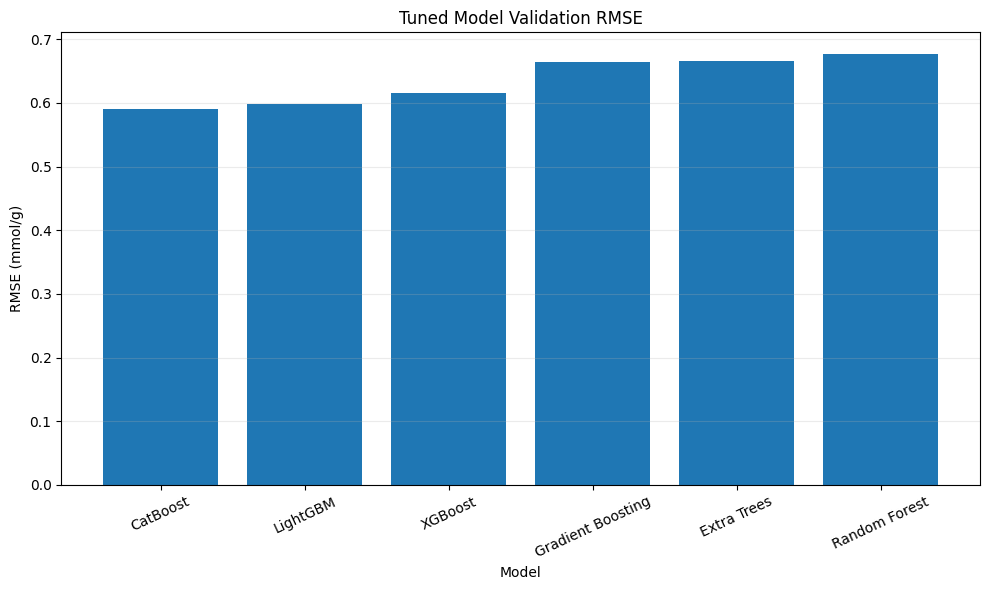

Saved: results/figures/tuned_model_validation_rmse.png


In [11]:

import matplotlib.pyplot as plt

plot_df = tuned_comparison_df.sort_values("Validation_RMSE")

fig, ax = plt.subplots(figsize=(10, 6))
ax.bar(plot_df["Model"], plot_df["Validation_RMSE"])

ax.set_title("Tuned Model Validation RMSE")
ax.set_xlabel("Model")
ax.set_ylabel("RMSE (mmol/g)")
ax.tick_params(axis="x", rotation=25)
ax.grid(axis="y", alpha=0.25)

fig.tight_layout()

plot_path = RESULTS_DIR / "figures" / "tuned_model_validation_rmse.png"
plot_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(plot_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", plot_path.relative_to(PROJECT_ROOT))


In [12]:

best_tuned = tuned_comparison_df.iloc[0]

tuning_summary = {
    "notebook": "06_hyperparameter_tuning.ipynb",
    "random_state": RANDOM_STATE,
    "trials_per_model": N_TRIALS,
    "cross_validation_folds": N_SPLITS,
    "optimization_metric": "RMSE",
    "target": TARGET_COLUMN,
    "features": FEATURE_COLUMNS,
    "training_rows": int(len(X_train)),
    "validation_rows": int(len(X_val)),
    "test_rows_reserved": int(len(test_df)),
    "test_set_used_for_tuning": False,
    "best_tuned_model_by_validation_rmse": str(best_tuned["Model"]),
    "best_validation_rmse": float(best_tuned["Validation_RMSE"]),
    "best_validation_mae": float(best_tuned["Validation_MAE"]),
    "best_validation_r2": float(best_tuned["Validation_R2"]),
    "model_names": model_names,
}

summary_path = RESULTS_DIR / "hyperparameter_tuning_summary.json"
with open(summary_path, "w", encoding="utf-8") as file:
    json.dump(tuning_summary, file, indent=4, ensure_ascii=False)

print("Tuning completed.")
print("Best tuned model:", tuning_summary["best_tuned_model_by_validation_rmse"])
print(f"Validation RMSE: {tuning_summary['best_validation_rmse']:.4f}")
print(f"Validation MAE: {tuning_summary['best_validation_mae']:.4f}")
print(f"Validation R²: {tuning_summary['best_validation_r2']:.4f}")
print("Summary saved:", summary_path.relative_to(PROJECT_ROOT))


Tuning completed.
Best tuned model: CatBoost
Validation RMSE: 0.5898
Validation MAE: 0.3909
Validation R²: 0.8466
Summary saved: results/hyperparameter_tuning_summary.json
